# Quantum Metal iSWAP example 3 — two crossmons and a tunable coupler, open readouts beside a through line (Quantcore PDK rebuild)

**What the chip is.** Example 3 of the Qiskit Metal notebook
`docs/circuit-examples/F.Small-quantum-chips/Full-Physical-Design-of-iSWAP-Gates.ipynb` (after Phys. Rev. X 11,
021058 (2021), Fig. 1; the same qubit / coupler pair as `D.Qubit-couplers/31-TwoCrossmonsTunableCoupler`; © IBM /
Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/iswap3_xmon_tc.md`; the notebook: "the point is the structure of each device, not its exact
geometry"). Two `TransmonCrossFL` crossmons 600 µm apart with a `TunableCoupler01` (C-shaped interdigitated island
with a SQUID and a flux line) above their inner arms. An east–west through line arches over the chip; the two
qubits' 2 mm readout meanders and the coupler's 1.5 mm meander end open (`OpenToGround`) next to it. Six
launchpads: the two through-line ends, Q1's flux line, a line on Q2's claw `b`, Q1's claw `b` and the coupler's flux
line. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example 3 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 4 × 3 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die, the source's chip area centred in it, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | six `LaunchpadWirebond`s on the 4 × 3 mm chip's edges (≈ 2–2.5 mm inside the die) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge they face (W, E, N, N, S, S); their lines get longer leads |
| junctions | Metal junction lines (10 nH assumed) | Quantcore trilayer SQUIDs (PDK: two 0.25 × 0.6 µm junctions, 45 kΩ in parallel) for both crossmons and the coupler |
| crossings | the two north lines cross the arch (a short in the source's mask) | a KQC airbridge at each crossing |
| cheese | none (the notebook never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RouteStraight` / `RouteMeander` (1.5 / 2 / 2 mm, 40 µm fillet) | qcc `cpw` routes on Metal's corner points (lengths kept; the pad leads grow) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options and relative positions, every route's end pins and
Metal's corner points (`RouteStraight` lines with their 250 µm leads, the three `RouteMeander`s with 90 µm spacing and
40 µm fillet: 1500 / 2000 / 2000 µm). All routes are 10/6 µm CPW (Metal's defaults).

**Simplified:** (1) Metal's through line (`RouteMeander` with six jogs) overshoots the west launchpad's tie and
doubles back to it (714 µm doubled stub under the pad in the source's screenshot); the rebuild ends the arch at the
tie. (2) The straight lines get a 20 µm fillet at their 45° corners (Metal draws them sharp). (3) The lines to the two
north pads cross the arch: each gets a KQC airbridge at the crossing (none in the source).

**Assumed couplings:** the coupler island's ends sit over the qubits' inner arms, and the inner arm tips face each
other across 200 µm; no route carries these, so they are declared with `d.couple` from coplanar-strip estimates
(rough). The Q3D job `Q1_TC_Q2` replaces them. The readout ends couple to the through line only through their 125 µm
gap to it (≈ 0.1 fF): not in the LOM, so their κ comes from the eigenmode job.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM → FEM job
→ results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.lom import estimates as est
CPW = dict(a=10, b=6)                            # Metal cpw_width / cpw_gap defaults

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame; the six launchpads go 100 µm from the edges they face; both crossmons and the coupler get a PDK trilayer SQUID; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
source's 4 × 3 mm chip fits the 7.5 mm Quantcore die, so the die is centred on it: `box=(-1750, -2250, 5750, 5250)`.
Metal centres its chip on (0, 0), so a Metal position (x, y) is `P(x, y)` = (2000 + x, 1500 + y) here.

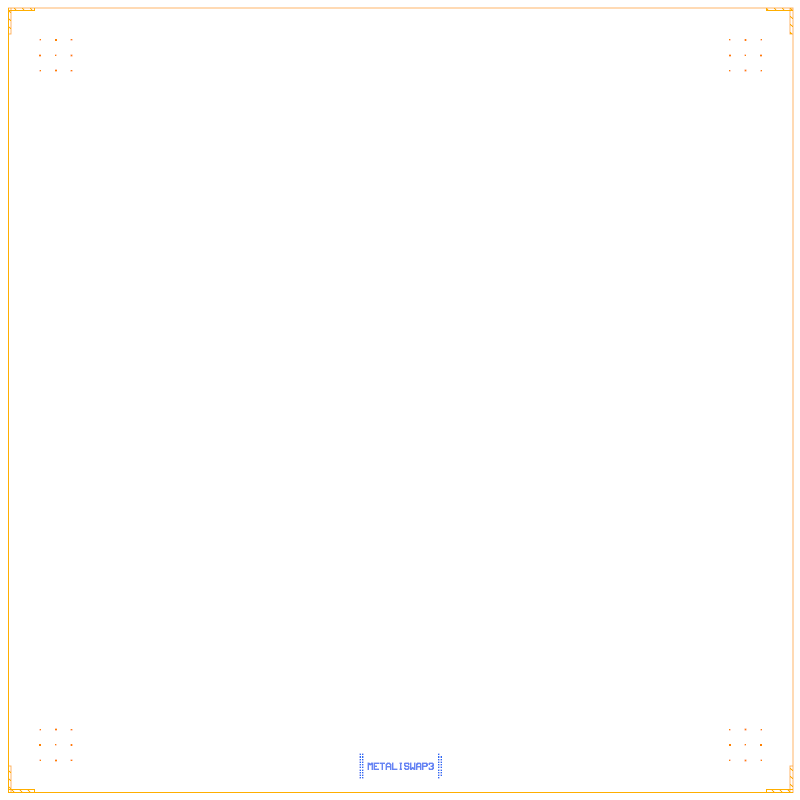

WindowsPath('examples/designs/metal/iswap3_xmon_tc_step_die.png')

In [4]:
d = Designer("iswap3_xmon_tc", box=(-1750, -2250, 5750, 5250), chip={"name_chip": "MetalISWAP3"}, live=LIVE)
X0, Y0 = 2000, 1500                              # Metal's 4 × 3 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PP = lambda pts: [P(x, y) for x, y in pts]
rebuild(d)
snap(d, OUT / "iswap3_xmon_tc_step_die.png", size=(800, 800), width=320)

## 4 · Pads: the PDK pad rule

The tutorial's six `LaunchpadWirebond`s sit on the edges of its 4 × 3 mm chip, 2–2.5 mm inside our die: the two
through-line pads point west / east, the four control pads north (`T_NE`, `T_NW`) and south (`T_SW`, `T_SE`). In the
Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**:
`edge="w"` / `"e"` / `"n"` / `"s"` slides each pad perpendicular to the edge it faces until it is there, keeping its
position along that edge (here `"auto"` would pick the same edges). The lines are routed to the pads' ties later, so
their last straight lead simply gets longer.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| T_west | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| T_east | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| T_NE | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| T_NW | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| T_SW | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| T_SE | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

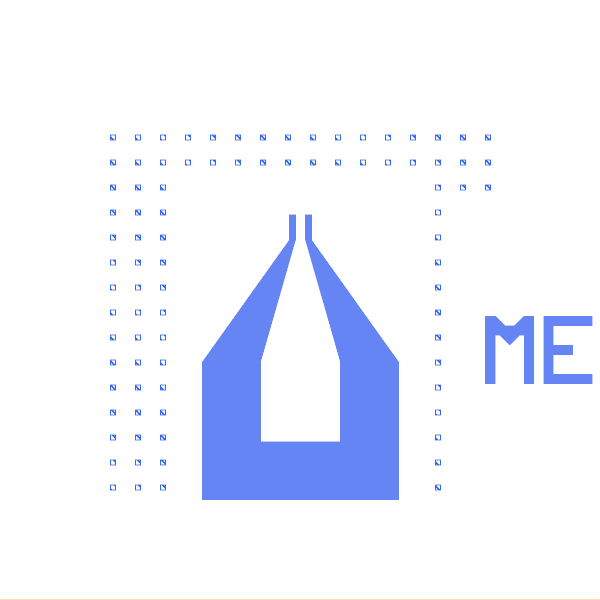

WindowsPath('examples/designs/metal/iswap3_xmon_tc_step_pads.png')

In [5]:
with d.batch():
    lp = {n: d.add(n, "metal:LaunchpadWirebond", at=P(x, y), rot=r, edge=e)
          for n, x, y, r, e in (("T_west", -1500, 0, 0, "w"), ("T_east", 1500, 0, 180, "e"),
                                ("T_NE", 500, 1000, -90, "n"), ("T_NW", -500, 1000, -90, "n"),
                                ("T_SW", -500, -1000, 90, "s"), ("T_SE", 500, -1000, 90, "s"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "T_SW.tie")
snap(d, OUT / "iswap3_xmon_tc_step_pads.png", box=(px - 300, -2250, px + 300, -1650), size=(600, 600), width=300)

## 5 · Components: two crossmons, the coupler and the open ends

**The qubits.** `metal:TransmonCrossFL` (a cross with a flux T-line), Q1 at (300, 0) and Q2 rotated 180° at
(−300, 0), each with a gap-type connector `b` (north) and a claw `c` (west, towards the readout). They are flux
tunable, so each gets a **PDK SQUID** (`trilayer_junction(..., squid=True)`: two 0.25 × 0.6 µm trilayer junctions,
45 kΩ in parallel, L_J 6.73 nH at zero flux, C_J 15 fF); `junction=` carries L_J / C_J to the LOM. The tutorial gives
no target frequency (estimate ≈ 5.8 GHz with the PDK SQUID; the assumed 10 nH gave 5.08 GHz).

**The claw vs the arm (PDK `pdk_claw`).** A `TransmonCross` claw longer than the arm reach (arm + ground spacing −
half the arm width = 195 µm with the defaults) runs into the side arms' gap; the fix is a longer
`cross_length`. The claws here are Metal's default 30 µm: far inside.

**The coupler.** `metal:TunableCoupler01` above the inner arms (`a_height` 100 µm), with its own PDK SQUID.

**The open ends.** Three `metal:OpenToGround`s terminate the readout / coupler meanders beside the through line.

SQUID: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['b', 'c', 'flux_line', 'squid_a', 'squid_b'] | TC ports: ['Control', 'Flux', 'squid_a', 'squid_b']


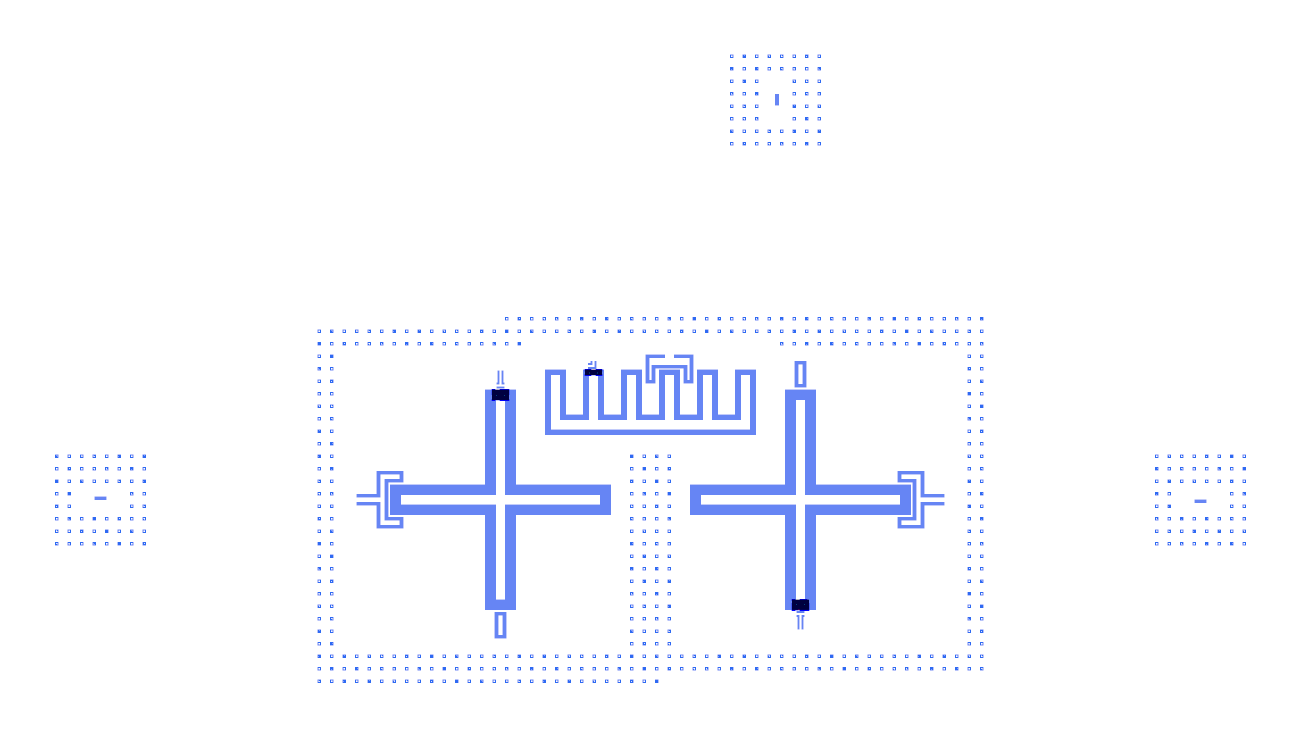

WindowsPath('examples/designs/metal/iswap3_xmon_tc_step_parts.png')

In [6]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
# flux-tunable qubits / couplers: a Quantcore SQUID of two junctions, R_n 45 kΩ in parallel (L_J 6.73 nH at zero
# flux, C_J 15 fF); SQ_PARAMS = {"junction_type": "Quantcore Squid", "junction_params": {"lj_nH": 6.73}}
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)
print("SQUID:", SQ_PARAMS, SQUID)
with d.batch():
    pads = {"b": {"connector_location": "90", "connector_type": "1"},
            "c": {"connector_location": "180", "connector_type": "0"}}
    q1 = d.add("Q1", "metal:TransmonCrossFL", at=P(300, 0), junction=SQUID, **SQ_PARAMS, connection_pads=pads)
    q2 = d.add("Q2", "metal:TransmonCrossFL", at=P(-300, 0), rot=180, junction=SQUID, **SQ_PARAMS, connection_pads=pads)
    tc = d.add("TC", "metal:TunableCoupler01", at=P(0, 150), a_height=100, junction=SQUID, **SQ_PARAMS)
    otg = {n: d.add(n, "metal:OpenToGround", at=P(x, y), rot=r)
           for n, x, y, r in (("open1", 250, 800, 0), ("open2", 1100, 0, -90), ("open3", -1100, 0, 90))}
print("Q1 ports:", sorted(q1.ports), "| TC ports:", sorted(tc.ports))
snap(d, OUT / "iswap3_xmon_tc_step_parts.png", box=P(-1300, -500) + P(1300, 1000), size=(1300, 750), width=520)

## 6 · Routes, couplings and sim groups

- **Straight control lines** to the four north / south pads (Metal `RouteStraight`, 250 µm leads; a 20 µm fillet at
  the 45° corners). The two north lines cross the through line's arch (y = 853.55 µm, Metal frame): a waypoint with
  `airbridge=True` puts a KQC airbridge there.
- **The through line** from `T_east` to `T_west` along Metal's arch, ending at the west tie.
- **The open meanders** (Metal `RouteMeander` corner points, 40 µm fillet): Q1's and Q2's 2 mm readouts and the
  coupler's 1.5 mm line, each ending on its `OpenToGround`.
- **Couplings no route carries** (coplanar-strip estimates, rough): coupler island ↔ each qubit's inner arm, and the
  inner arm tips end-on.
- **Sim groups:** the qubit / coupler core (Q3D C-matrix) and Q1 with its open meander (eigenmode).

C(TC ↔ Q): 2.28 fF;  C(Q1 ↔ Q2): 1.56 fF (estimates)


route lengths (µm): {'cpw_1': 3183.3, 'cpw_2': 3166.8, 'cpw_3': 3166.8, 'cpw_4': 3318.6, 'tline': 8002.3, 'coupler_mid': 1500.0, 'coupler_right': 2000.0, 'coupler_left': 2000.0}


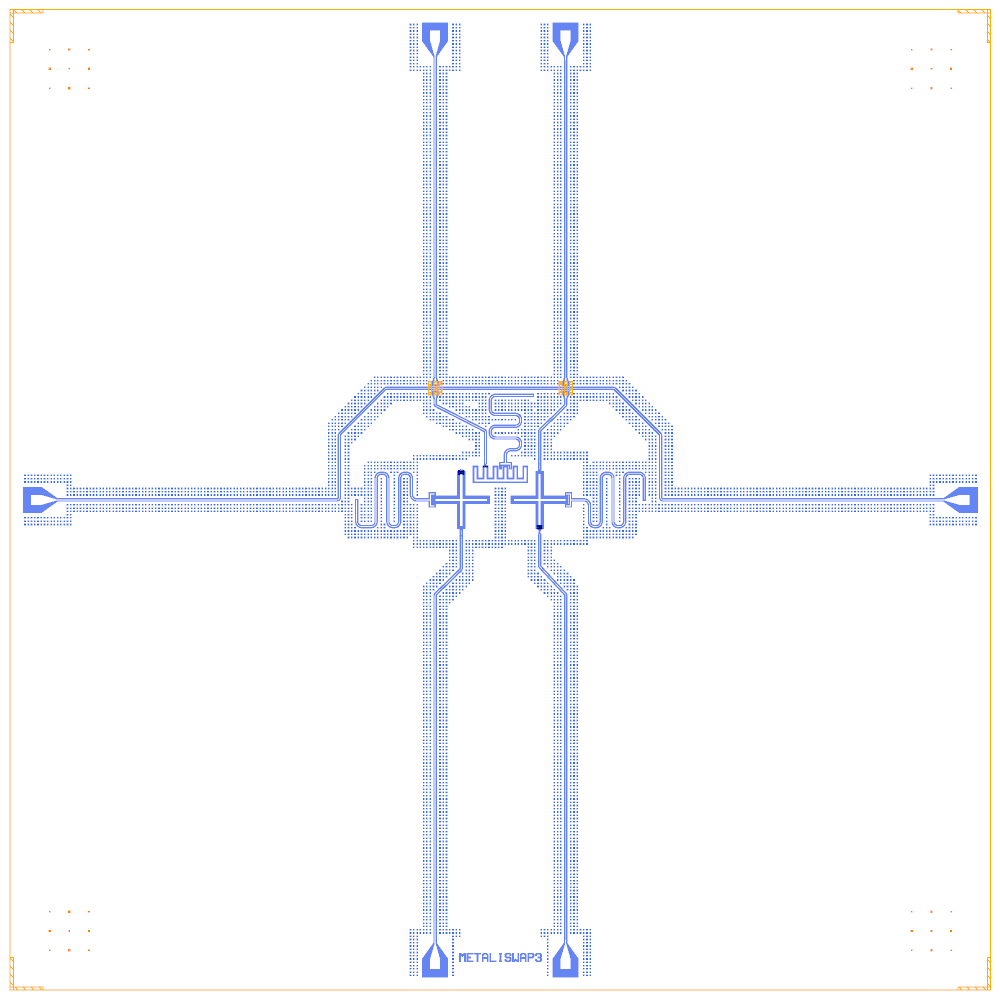

WindowsPath('examples/designs/metal/iswap3_xmon_tc_step_routes.png')

In [7]:
EPS = est.substrate_eps(get_pdk())
# coupler island (10 µm bottom bar, ±206 µm wide, 132 µm above the axis) over a qubit's inner arm (20 µm wide, tip at
# ±100 µm): ≈ 106 µm overlap, ≈ 120 µm apart with the ground strip between the two pockets (screening 0.5, rough)
C_TC = round(est.coplanar_coupling(106, 20, 10, 120, EPS, screening=0.5), 2)
# inner arm tips end-on: 20 µm facing width (cross_width), 200 µm apart, 200 µm deep each
C_QQ = round(est.coplanar_coupling(20, 200, 200, 200, EPS), 2)
print("C(TC ↔ Q):", C_TC, "fF;  C(Q1 ↔ Q2):", C_QQ, "fF (estimates)")
with d.batch():
    # straight lines to the bottom pads (Metal RouteStraight, 250 µm leads)
    d.route("cpw_1", q1.flux_line, lp["T_SE"].tie, r=20, nodes=PP([(300, -508.5), (500, -725)]), **CPW)
    d.route("cpw_2", q2.b, lp["T_SW"].tie, r=20, nodes=PP([(-300, -531), (-500, -725)]), **CPW)
    # the two north lines cross the through line's arch (y = 853.55): an airbridge each (none in the source)
    AB = lambda x: d.waypoint(P(x, 853.55), airbridge=True)
    d.route("cpw_3", q1.b, lp["T_NE"].tie, r=20, nodes=PP([(300, 531), (500, 725)]) + [AB(500)], **CPW)
    d.route("cpw_4", tc.Flux, lp["T_NW"].tie, r=20, nodes=PP([(-114, 527.5), (-500, 725)]) + [AB(-500)], **CPW)
    # the east-west through line (Metal's arch, ending at the west tie)
    d.route("tline", lp["T_east"].tie, lp["T_west"].tie, r=20, **CPW,
            nodes=PP([(1225, 0), (1225, 500), (871.45, 853.55), (-878.55, 853.55), (-1232.11, 500), (-1232.11, 0)]))
    # the open-ended meanders beside it (Metal RouteMeander corner points, fillet 40 µm)
    d.route("coupler_mid", tc.Control, otg["open1"].open, r=40, **CPW,
            nodes=PP([(38, 384), (153.81, 384), (153.81, 474), (-77.81, 474), (-77.81, 564), (153.81, 564),
                      (153.81, 654), (-77.81, 654), (-77.81, 800)]))
    right = [(681, 0), (681, -204.44), (771, -204.44), (771, 204.44), (861, 204.44), (861, -204.44), (951, -204.44),
             (951, 204.44), (1100, 204.44)]
    d.route("coupler_right", q1.c, otg["open2"].open, r=40, nodes=PP(right), **CPW)
    d.route("coupler_left", q2.c, otg["open3"].open, r=40, nodes=PP([(-x, -y) for x, y in right]), **CPW)
    # couplings no route carries (estimates, see the markdown)
    d.couple("Cg_Q1_TC", "Q1", "TC", C_fF=C_TC, note="coupler island end over Q1's inner arm (CPS estimate)")
    d.couple("Cg_Q2_TC", "Q2", "TC", C_fF=C_TC, note="coupler island end over Q2's inner arm (CPS estimate)")
    d.couple("Cg_Q1_Q2", "Q1", "Q2", C_fF=C_QQ, note="inner arm tips end-on, 200 µm (CPS estimate)")
# FEM boxes: the qubit / coupler core (cuts each line once), and the right readout with its open end and the line
d.sim_group("Q1_TC_Q2", ["Q1", "Q2", "TC"], margin_um=40, analyses=["q3d_cmatrix"])
d.sim_group("Q1_read", ["Q1", "coupler_right", "open2"], margin_um=40, analyses=["eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "iswap3_xmon_tc_step_routes.png", size=(1000, 1000), width=400)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. The die is already centred on the source's chip and the pads now
sit symmetrically on all four edges, so `center_in_die` finds the content centred (a shift under its 50 µm tolerance
is not applied) and moves nothing. Then the design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
X0, Y0 = X0 + shift[0], Y0 + shift[1]            # keep P(x, y) = Metal → Designer after the shift
DESIGN = d.save(OUT / "iswap3_xmon_tc.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm
<Designer iswap3_xmon_tc: 12 instances, 8 routes, live=False> → examples\designs\metal\iswap3_xmon_tc.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; `dangling_port` warnings for the junction attachment points `squid_a` /
`squid_b` of Q1, Q2 and TC (drawn by the cells, not route ends) and Q2's unused flux line; two `overlap` warnings,
the coupler's bounding box over Q1's and Q2's (it sits above their inner arms, as in the source; the metal does not
touch). **No PDK design warnings:** the six pads are at 100 µm (`pad_edge`); each PDK SQUID (two 90 kΩ junctions)
is 45 kΩ in parallel, inside the 40–50 kΩ window (`pdk_rn` checks the device); no targets (`pdk_fq`); 30 µm claws
on 200 µm arms (`pdk_claw`).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 9 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 7 | Q1.squid_a is not connected (no route or snap) |
| warning | `overlap` | 2 | Q1 and TC overlap |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 3 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: `TransmonCrossFL` → a grounded cross island with its SQUID, a node
per claw, the flux line as a control; `TunableCoupler01` → a grounded island + SQUID, the `Control` claw as a node,
`Flux` as a control. Each claw → open-end meander is a λ/2 `TLres` (open at the claw and at the `OpenToGround`: 2 mm ≈
32 GHz, 1.5 mm ≈ 43 GHz, far above the qubits, as the source's lengths are); Q2's claw `b` line ends on its 50 Ω pad.
The three `d.couple` capacitances join the coupler island to both qubits and the qubits to each other.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "TC."))})

**10 nodes · 26 branches · 2 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `tline` | `tline`, `T_west.pad`, `T_east.pad` |
| `Q1.b` | `T_NE.pad`, `Q1.b` |
| `Q2.b` | `T_SW.pad`, `Q2.b` |
| `Q1` | `Q1.island` |
| `Q1.c` | `Q1.c`, `open2.end` |
| `Q2` | `Q2.island` |
| `Q2.c` | `Q2.c`, `open3.end` |
| `TC` | `TC.island` |
| `TC.Control` | `TC.Control`, `open1.end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_T_west` | R | `tline` – `gnd` | 50 Ω |
| `Port_T_east` | R | `tline` – `gnd` | 50 Ω |
| `Port_T_NE` | R | `Q1.b` – `gnd` | 50 Ω |
| `Port_T_SW` | R | `Q2.b` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 86.9 fF |
| `J_Q1` | SQUID | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_b` | C | `Q1` – `Q1.b` | 0.095 fF |
| `Cc_Q1_b` | C | `Q1.b` – `gnd` | 11.8 fF |
| `Cg_Q1_c` | C | `Q1` – `Q1.c` | 1.1 fF |
| `Cc_Q1_c` | C | `Q1.c` – `gnd` | 29.8 fF |
| `C_Q2` | C | `Q2` – `gnd` | 86.9 fF |
| `J_Q2` | SQUID | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_b` | C | `Q2` – `Q2.b` | 0.095 fF |
| `Cc_Q2_b` | C | `Q2.b` – `gnd` | 11.8 fF |
| `Cg_Q2_c` | C | `Q2` – `Q2.c` | 1.1 fF |
| `Cc_Q2_c` | C | `Q2.c` – `gnd` | 29.8 fF |
| `C_TC` | C | `TC` – `gnd` | 34 fF |
| `J_TC` | SQUID | `TC` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_TC_Control` | C | `TC` – `TC.Control` | 6 fF |
| `Cc_TC_Control` | C | `TC.Control` – `gnd` | 7.6 fF |
| `C_Cg_Q1_TC` | C | `Q1` – `TC` | 2.28 fF |
| `C_Cg_Q2_TC` | C | `Q2` – `TC` | 2.28 fF |
| `C_Cg_Q1_Q2` | C | `Q1` – `Q2` | 1.56 fF |
| `coupler_mid` | TLres | `TC.Control` – `gnd` | lambda/2, 1500 µm, 42.012 GHz |
| `coupler_right` | TLres | `Q1.c` – `gnd` | lambda/2, 2000 µm, 31.509 GHz |
| `coupler_left` | TLres | `Q2.c` – `gnd` | lambda/2, 2000 µm, 31.509 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `cpw_1` | flux_bias | `J_Q1` | `cpw_1` | 3183 |
| `cpw_4` | flux_bias | `J_TC` | `cpw_4` | 3319 |

**Unconnected ports:** none

**Builder notes:**

- Port_T_NW: both ends on gnd after merging conductors (dropped)
- Port_T_SE: both ends on gnd after merging conductors (dropped)

{'Q1.squid_a': 'Q1', 'Q1.squid_b': 'gnd', 'Q1.b': 'Q1.b', 'Q1.c': 'Q1.c', 'Q1.flux_line': 'control:flux', 'TC.squid_a': 'TC', 'TC.squid_b': 'gnd', 'TC.Control': 'TC.Control', 'TC.Flux': 'control:flux'}


## 10 · LOM simulation

Each qubit and the coupler with its open meander, then Q1–coupler–Q2 (static ZZ). The meanders are λ/2 far above the
qubits and couple to the through line only geometrically, so they are not readouts in the LOM (κ 0, χ small).

- Q1 / Q2 with the PDK SQUID ≈ 5.8 GHz (the assumed 10 nH gave 5.08 GHz); the coupler ≈ 7.9 GHz at zero flux.
- The two qubits are identical, so their modes hybridise through the coupler (and the direct arm coupling): ZZ is
  not defined for degenerate qubits. Both couplings are the rough estimates of step 6.

In [11]:
read = {"Q1+coupler_right": ["Q1", "coupler_right", "open2"], "Q2+coupler_left": ["Q2", "coupler_left", "open3"],
        "TC+coupler_mid": ["TC", "coupler_mid", "open1"]}
results = simulate_groups(d, read)
display(Markdown(groups_md(results)))
coupled = simulate_groups(d, {"Q1+TC+Q2": ["Q1", "TC", "Q2"]}, max_modes=3)
display(Markdown("**Q1–TC–Q2, QuCat normal modes:**\n\n" + modes_md(coupled["Q1+TC+Q2"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+coupler_right | Q1 | 5.8459 | -203.3 | coupler_right | 28.59 | 0 | -0.00573 |
| Q2+coupler_left | Q2 | 5.8459 | -203.3 | coupler_left | 28.59 | 0 | -0.00573 |
| TC+coupler_mid | TC | 7.8993 | -394.2 | coupler_mid | 39.704 | 0 | -0.847 |

**Q1–TC–Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.8891 | 0 | 89.3 | J_Q1 0.50, J_Q2 0.50 |
| Q2 | qubit | 5.9696 | 0 | 91.0 | J_Q1 0.50, J_Q2 0.50 |
| TC | qubit | 8.1448 | 0 | 338.7 | J_TC 1.00 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+TC+Q2 | Q1-Q2 | – | yes | yes |
| Q1+TC+Q2 | Q1-TC | – | yes | yes |
| Q1+TC+Q2 | Q2-TC | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs: a **Q3D C-matrix** for the two qubits and the coupler (it replaces the three assumed couplings; the
box cuts each line once) and an **eigenmode / EPR** job for Q1 with its open meander (the through line inside the box
ends in 50 Ω, so the mode Q gives the meander's κ into it). The exporter warns that it cannot draw the coupler's
junction port ("Unable to create polygon for port …"); `TC.island` is still a net of the C-matrix job.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN, ["Q1_TC_Q2"])
jobs_eig = export_sims(DESIGN, ["Q1_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_TC_Q2 | `build/jobs/iswap3_xmon_tc_Q1_TC_Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · junction · `TC.junction`<br>4 · edge · `coupler_left`<br>5 · edge · `coupler_mid`<br>6 · edge · `coupler_right`<br>7 · edge · `cpw_1`<br>8 · edge · `cpw_2`<br>9 · edge · `cpw_3`<br>10 · edge · `cpw_4` | `Q1.island`, `Q2.island`, `TC.island`, `coupler_left`, `coupler_mid`, `coupler_right`, `Q2.b`, `Q1.b` |
| Q1_read | `build/jobs/iswap3_xmon_tc_Q1_read_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `cpw_1`<br>3 · edge_lumped · `cpw_3` | `Q1.island`, `cpw_1`, `cpw_3`, `Q1.c`, `Q1.b` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q1_TC_Q2', 'Q1_read'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q1_TC_Q2 · q3d, Q1_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here Q1's arm length `cross_length`, 200 → 180 µm (the knob the PDK's `pdk_claw` fix turns the other way) — and re-run
the LOM of Q1 with its open meander. Shorter arms mean a smaller C_Σ: f_q and |α| go up. (A longer arm would push the
claw `c` into the first 90° turn of `coupler_right`, which starts on Metal's corner point 381 µm east of Q1's centre:
the router then reports that the straight segment cannot fit.)

In [15]:
d2 = design_copy(DESIGN)
d2["Q1"].set(cross_length=180)                   # 200 µm (Metal default) → 180 µm
res2 = simulate_groups(d2, {"Q1+coupler_right": read["Q1+coupler_right"]})
display(Markdown(params_delta_md({"Q1+coupler_right": results["Q1+coupler_right"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+coupler_right: Q1.f_q_GHz` | 5.8459 | 6.1061 | +0.2602 |
| `Q1+coupler_right: Q1.alpha_MHz` | -203.27 | -223.4 | -20.13 |
| `Q1+coupler_right: coupler_right.chi_MHz` | -0.0057277 | -0.0072491 | -0.001521 |
| `Q1+coupler_right: coupler_right.f_GHz` | 28.59 | 28.332 | -0.2582 |
| `Q1+coupler_right: coupler_right.kappa_MHz` | 0 | 0 | +0 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The iSWAP notebook never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). The two airbridges export to 300/0
+ 301/0.

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\iswap3_xmon_tc.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 6266 |
| 2/0 | JJ_STRAIGHT | 3 |
| 3/0 | M3 | 6240 |
| 4/0 | JJ_BENT | 3 |
| 50/0 | HSQ | 12 |
| 51/0 | SPACER_1 | 12 |
| 52/0 | SPACER_2 | 12 |
| 53/0 | SPACER_3 | 12 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 12 |
| 301/0 | AIRBRIDGE_BRIDGE | 6 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 6236 holes on the mask.

→ `build/iswap3_xmon_tc_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's last screenshot; the pads now on the die edges); the two crossmons with the
coupler above their inner arms; a SQUID; the airbridge where Q1's north line crosses the arch; the **fab mask** of
the core (1/0 etch with the PDK cheese band, the 3/0 keep-out, the junction layers); and the die frame's south-west
corner (dicing L on 1000/0, alignment grid on 1001/0).

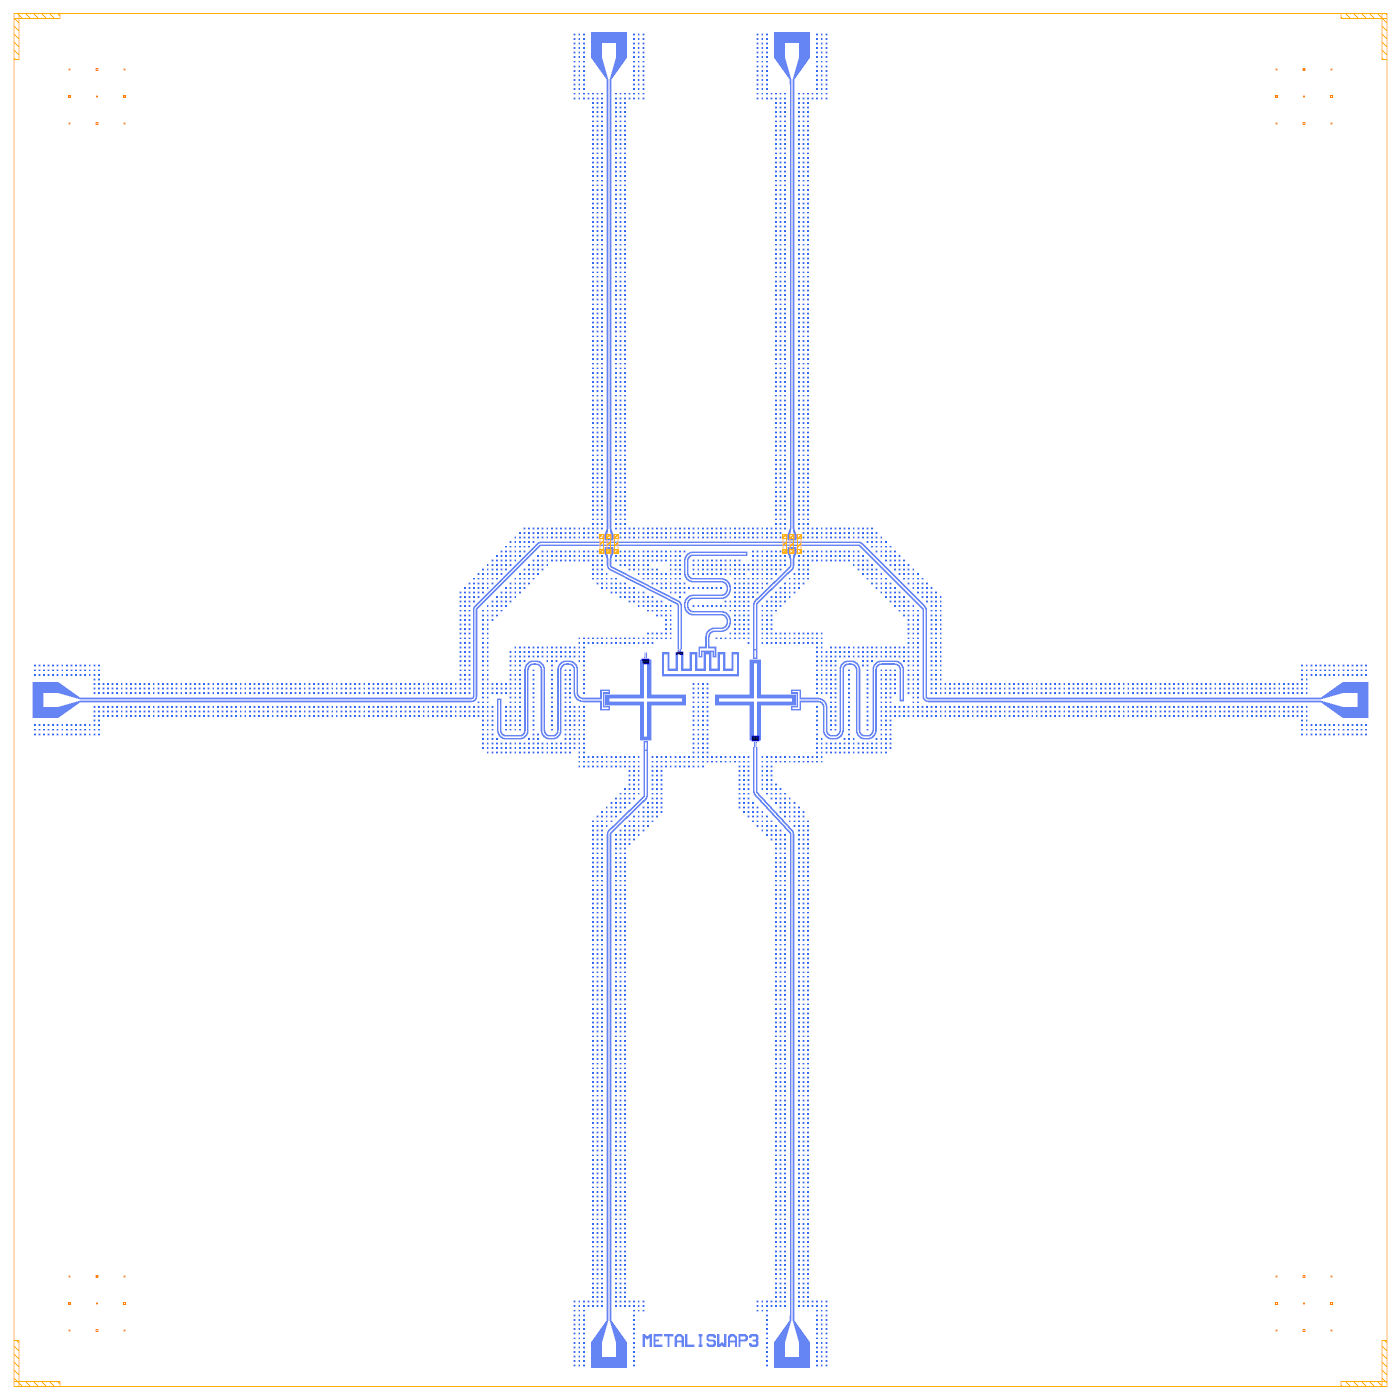

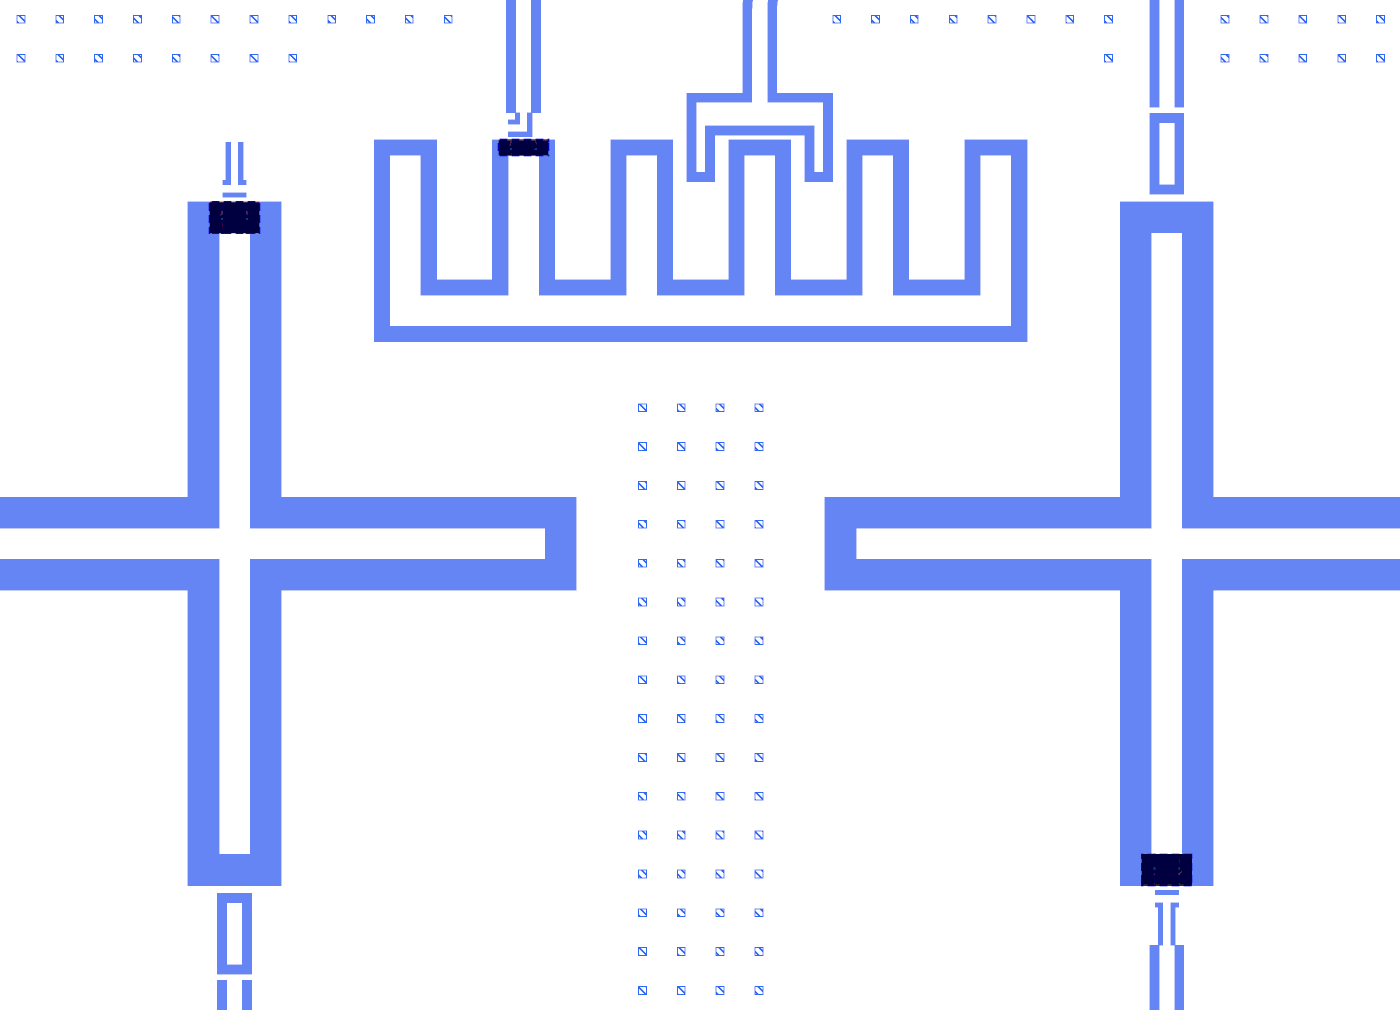

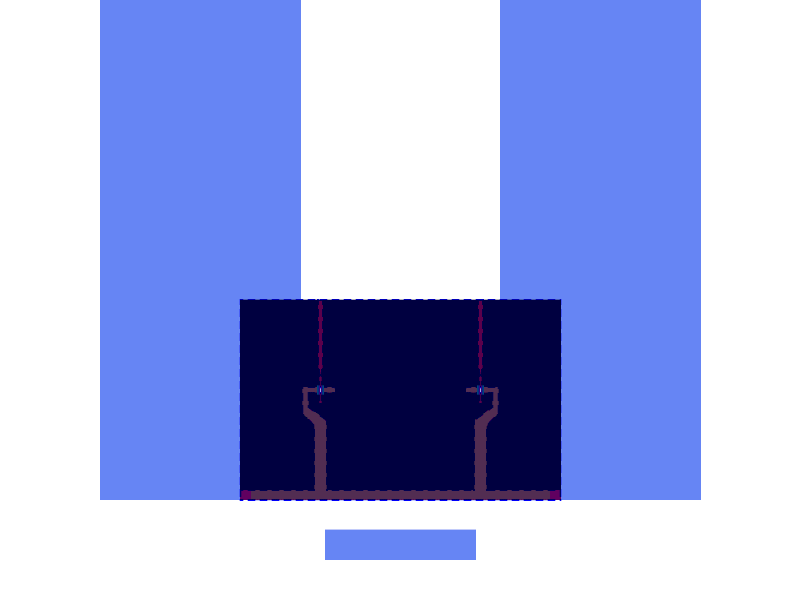

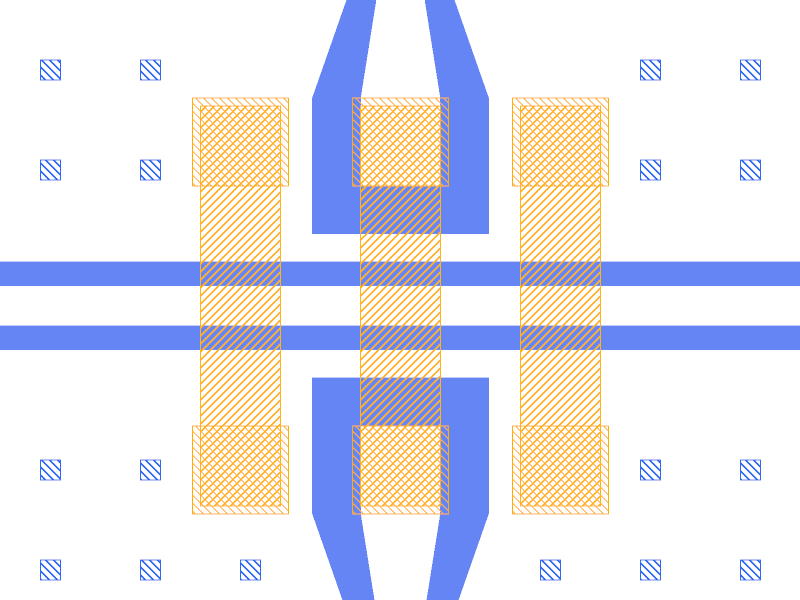

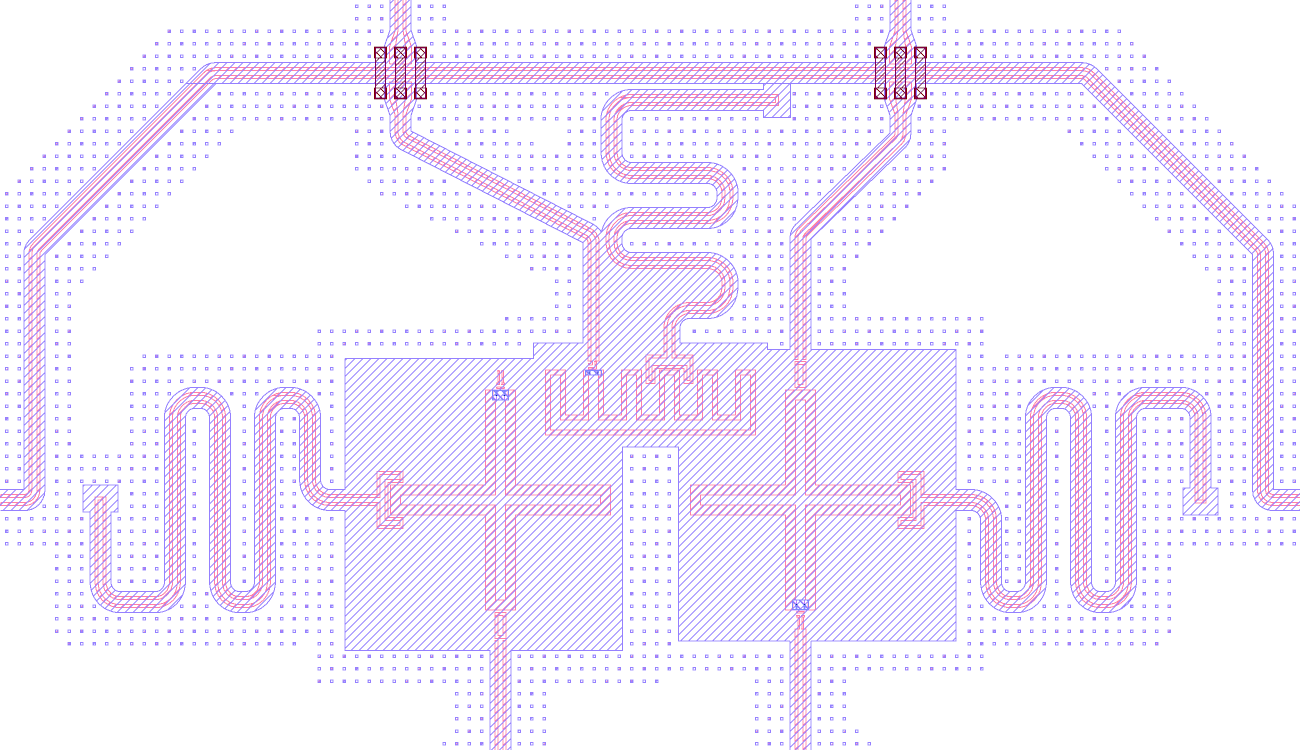

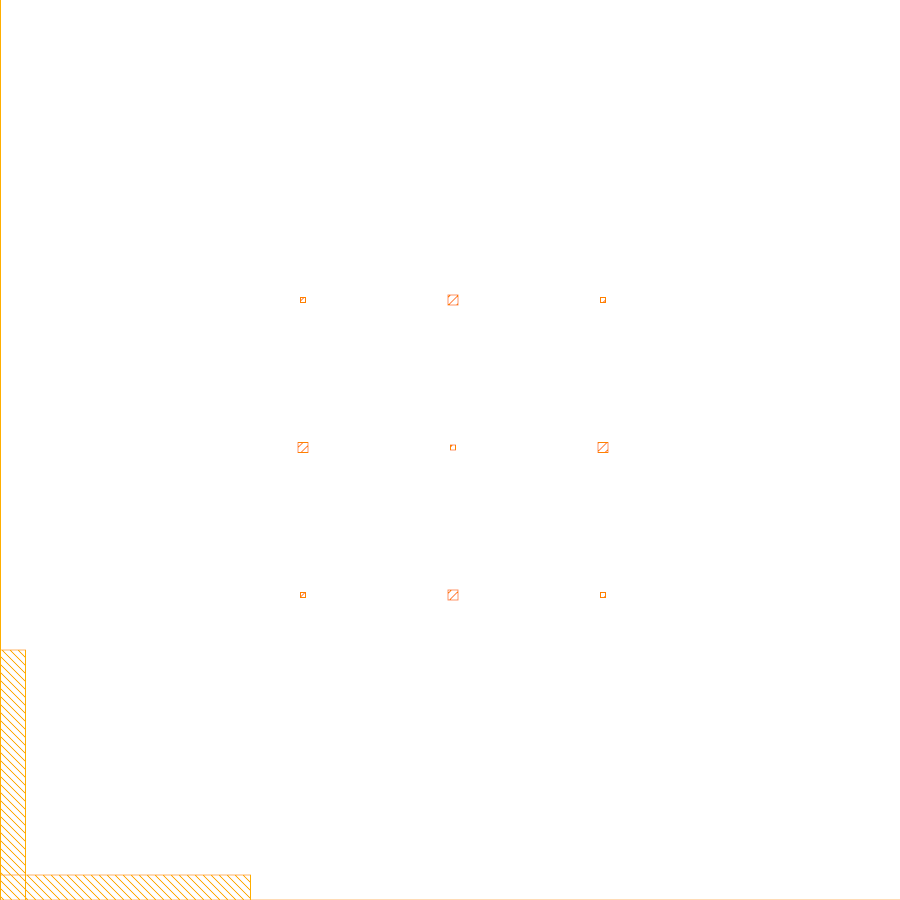

In [17]:
show_snapshot(d, OUT / "iswap3_xmon_tc.png", size=(1400, 1400))
show_snapshot(d, OUT / "iswap3_xmon_tc_core.png", box=P(-450, -300) + P(450, 350), size=(1400, 1010), width=520)
show_snapshot(d, OUT / "iswap3_xmon_tc_jj.png", box=P(260, -230) + P(340, -170), size=(800, 600), width=300)
show_snapshot(d, OUT / "iswap3_xmon_tc_bridge.png", box=P(400, 780) + P(600, 930), size=(800, 600), width=300)
snap_file(Path("build") / "iswap3_xmon_tc_fab.oas", OUT / "iswap3_xmon_tc_cheese.png",
          box=P(-1300, -500) + P(1300, 1000), size=(1300, 750), width=520)
show_snapshot(d, OUT / "iswap3_xmon_tc_frame.png", box=(-1750, -2250, -850, -1350), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, every route's end pins and Metal corner points (the 1.5 / 2 / 2 mm open meanders, the arch), the sim groups |
| PDK changes | the 7.5 mm die with the QCT frame; sapphire stack; the six launchpads 100 µm from the W / E / N / S edges (were 1990–2490 µm in); trilayer SQUIDs (PDK) for both crossmons and the coupler; PDK cheese band; content centred (no shift needed) |
| differs | the pad leads are 2–2.5 mm longer; airbridges at the two arch crossings; the arch ends at the west tie; f_q ≈ 5.8 GHz with the PDK SQUID (the assumed 10 nH gave 5.08 GHz) |
| PDK design warnings | none |
| open | the couplings are CPS estimates until the Q3D job is solved (`RUN_FEM = False`) |